In [1]:
import numpy as np 
import pandas as pd

In [2]:
file = 'startup_funding.csv'
df = pd.read_csv(file)

In [3]:
df.head()

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
1,2020-01-09,BYJU'S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,1650,2020,1
2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,66,2020,1
3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,151,2020,1
4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,25,2020,1
5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,15,2020,1


In [4]:
df.shape

(2856, 10)

In [5]:
df['Startup Name'].unique().shape

KeyError: 'Startup Name'

#### Fix BYJU'S Col

In [ ]:
df[df['Startup Name'].str.startswith('BYJU') | df['Startup Name'].str.startswith('Byju')]

In [ ]:
# Step 1: Remove any accidental leading/trailing quotes or whitespace first
df['Startup Name'] = df['Startup Name'].str.strip('"\' ')

# Step 2: Standardize all variations starting with BYJU / Byju to 'BYJU'S'
df['Startup Name'] = df['Startup Name'].str.replace(
    r'^[Bb][Yy][Jj][Uu].*', 
    "BYJU'S", 
    regex=True
)

In [ ]:
# Check all rows containing BYJU (case-insensitive)
df[df['Startup Name'].str.contains('BYJU', case=False, na=False)]

In [ ]:
df.to_csv(file, index=False)
print("Changes saved successfully to CSV!")

#### Fix Flipkart Col

In [ ]:
df[df['Startup Name'].str.contains('Flipkart')]

In [ ]:
df['Startup Name'] = df['Startup Name'].str.replace("Flipkart.com", "Flipkart")

In [ ]:
df[df['Startup Name'].str.contains('Flipkart')]

In [ ]:
df.to_csv(file, index=False)
print("Changes saved successfully to CSV!")

In [ ]:
df[df['Startup Name'].str.contains('Fame')]

#### Fix Lenskart Col

In [ ]:
df[df['Startup Name'].str.contains('Lens')]

In [ ]:
# Map exact known variations to the clean name
lenskart_mapping = {
    'LensKart': 'Lenskart',
    'Lenskart.com': 'Lenskart',
}

df['Startup Name'] = df['Startup Name'].replace(lenskart_mapping)

In [ ]:
df[df['Startup Name'].str.contains('Lensk')]

In [ ]:
df.to_csv(file, index=False)
print("Changes saved successfully to CSV!")

In [ ]:
df[df['Startup Name'].str.contains('Ameyo')]

In [ ]:
# 1. Clean up \xc2\xa0 (non-breaking spaces) across the entire dataframe string columns
df = df.replace(r'\\xc2\\xa0', '', regex=True)
# Alternatively, if they are actual unicode characters in memory:
df = df.replace(r'\xa0', '', regex=True)

In [ ]:
df[df['Startup Name'].str.contains('Ameyo')]

In [ ]:
df['Startup Name'] = df['Startup Name'].str.replace(r'.*Ameyo.*', 'Ameyo', regex=True)

In [ ]:
df[df['Startup Name'].str.contains('Ameyo')]

In [ ]:
df.to_csv(file, index=False)
print("Changes saved successfully to CSV!")

#### Fix Encoding & Escape Artifacts in Startup Name (\\xc2\\xa0, \\xe2\\x80\\x99, \\n, etc.)

In [ ]:
# Check rows containing escape sequences or hex artifacts before cleaning
df[df['Startup Name'].str.contains(r'\\|xc2|xa0', regex=True, na=False)][['Startup Name']]

In [ ]:
# Clean up encoding artifacts, non-breaking space bytes, smart quotes, and dangling backslashes
df['Startup Name'] = (df['Startup Name']
                      .astype(str)
                      .str.replace(r'\\+xc2\\+xa0', ' ', regex=True)      # Fix \xc2\xa0 hex non-breaking spaces
                      .str.replace(r'\\+xa0', ' ', regex=True)             # Fix \xa0 escape sequences
                      .str.replace(r'\xa0', ' ', regex=True)               # Fix raw \xa0 characters
                      .str.replace(r'\\+xe2\\+x80\\+x99', "'", regex=True) # Fix smart quotes/apostrophes
                      .str.replace(r'\\+x99', "'", regex=True)
                      .str.replace(r'\\+n', ' ', regex=True)               # Fix escaped newlines
                      .str.replace(r'\\+', '', regex=True)                 # Remove leftover backslashes
                      .str.replace(r'^\s+|\s+$', '', regex=True)           # Trim leading and trailing whitespace
                      .str.strip('"\' ')
)

In [ ]:
# Verify that no backslashes or hex encoding artifacts remain
df[df['Startup Name'].str.contains(r'\\|xc2|xa0', regex=True, na=False)][['Startup Name']]

In [ ]:
df.to_csv(file, index=False)
print("Encoding artifacts cleaned and changes saved successfully to CSV!")

#### Fix Duplicate Startup Names with Spacing & Casing Inconsistencies (e.g., Avail Finance vs AvailFinance)

In [ ]:
# Check startup names that have spacing differences (e.g. 'Avail Finance' vs 'AvailFinance')
df[df['Startup Name'].str.contains('Avail', case=False, na=False)]['Startup Name'].unique()

In [ ]:
# Standardize startup names where spacing, casing, or known naming variants differ
startup_name_mapping = {
    # Spacing fixes (e.g. Avail Finance, Aye Finance, BigBasket, Ola Cabs, etc.)
    'AvailFinance': 'Avail Finance',
    'AYE Finance': 'Aye Finance',
    'AyeFinance': 'Aye Finance',
    'Bank Bazaar': 'BankBazaar',
    'BhiveWorkspace': 'BHIVE Workspace',
    'Big Basket': 'BigBasket',
    'Biteclub': 'Bite Club',
    'Book My Show': 'BookMyShow',
    'Box My Space': 'BoxMySpace',
    'Boxmyspace': 'BoxMySpace',
    'ChaiPoint': 'Chai Point',
    'Credit Mate': 'CreditMate',
    'Credit Vidya': 'CreditVidya',
    'Cure Fit': 'CureFit',
    'Curefit': 'CureFit',
    'Daily hunt': 'DailyHunt',
    'Daily Ninja': 'DailyNinja',
    'Daily Rounds': 'DailyRounds',
    'DoctorInsta': 'Doctor Insta',
    'Early Salary': 'EarlySalary',
    'Fab Hotels': 'FabHotels',
    'GlamStudios': 'Glam Studios',
    'Hansel io': 'Hansel.io',
    'HappilyUnmarried': 'Happily Unmarried',
    'High Radius': 'HighRadius',
    'i2i Funding': 'i2iFunding',
    'i2ifunding': 'i2iFunding',
    'icanstay': 'I Can Stay',
    'ImpactGuru': 'Impact Guru',
    'India Lends': 'IndiaLends',
    'Ink Monk': 'Inkmonk',
    'IntelligenceNODE': 'Intelligence Node',
    'JollyFoodFellow': 'Jolly Food Fellow',
    'Legalraasta': 'Legal Raasta',
    'LenDen Club': 'LenDenClub',
    'Lending Kart': 'Lendingkart',
    'LendingKart': 'Lendingkart',
    'Lets Transport': 'LetsTransport',
    'Loan Tap': 'LoanTap',
    'Loantap': 'LoanTap',
    'Logic Roots': 'LogicRoots',
    'Milk Basket': 'Milkbasket',
    'MilkBAsket': 'Milkbasket',
    'MilkBasket': 'Milkbasket',
    'MInd Your Fleet': 'MindYourFleet',
    'NewsInShorts': 'News in shorts',
    'Ola': 'Ola Cabs',
    'Olacabs': 'Ola Cabs',
    'Oyo': 'OYO Rooms',
    'Oyo Rooms': 'OYO Rooms',
    'OyoRooms': 'OYO Rooms',
    'Oyorooms': 'OYO Rooms',
    'Phone Pe': 'PhonePe',
    'PineLabs': 'Pine Labs',
    'Pipa Bella': 'Pipa Bella',
    'Policy Bazaar': 'PolicyBazaar',
    'RAW Pressery': 'Raw Pressery',
    'RawPressery': 'Raw Pressery',
    'Renew Buy': 'RenewBuy',
    'RollMafia': 'Roll Mafia',
    'ShubhLoans': 'Shubh Loans',
    'Spares Hub': 'SparesHub',
    'Stalk Buy Love': 'StalkBuyLove',
    'Tailslife': 'Tails Life',
    'Tea Box': 'Teabox',
    'Tone Tag': 'ToneTag',
    'Tonetag': 'ToneTag',
    'Travel Triangle': 'TravelTriangle',
    'Trip shelf': 'TripShelf',
    'UrbanLadder': 'Urban Ladder',
    'VanityCube': 'Vanity Cube',
    'WoWexpress': 'WoW Express',
    'Wow Express': 'WoW Express',
    'Zest Money': 'ZestMoney',

    # Specific known name cleanups
    "Faaso's": "Faasos",
    "NearBuy (previously  groupon India)": "Nearbuy",
    "NearBuy": "Nearbuy",
    "Crowdfire (formerly Justunfollow)": "Crowdfire",
    "1mg (Healthkartplus)": "1mg",
    "Zebi (yet to launch)": "Zebi",
    "Alef Mobitech": "AlefMobitech",

    # Casing / punctuation standardization
    'Active AI': 'Active.ai',
    'Applop': 'AppLop',
    'Appsdaily': 'AppsDaily',
    'Babychakra': 'BabyChakra',
    'Betaout': 'BetaOut',
    'Betterplace': 'BetterPlace',
    'BlackBuck': 'Blackbuck',
    'Bluestone': 'BlueStone',
    'CCavenue': 'CCAvenue',
    'Careongo': 'CareonGO',
    'Cartrade': 'CarTrade',
    'ChargeBee': 'Chargebee',
    'Cleartax': 'ClearTax',
    'Coutloot': 'CoutLoot',
    'CoverFox': 'Coverfox',
    'CraftsVilla': 'Craftsvilla',
    'Credihealth': 'CrediHealth',
    'Crofarm': 'CroFarm',
    'Cropin': 'CropIn',
    'Crown-it': 'Crownit',
    'CrownIt': 'Crownit',
    'Dropkaffe': 'DropKaffe',
    'Easypolicy': 'EasyPolicy',
    'Edurev': 'EduRev',
    'Findyahan': 'FindYahan',
    'Fitmein': 'FitMeIn',
    'FreshBoxx': 'Freshboxx',
    'FreshDesk': 'Freshdesk',
    'Ftcash': 'FTCash',
    'Glowroad': 'GlowRoad',
    'GoQii': 'GOQii',
    'Goqii': 'GOQii',
    'Healthifyme': 'HealthifyMe',
    'healthifyme': 'HealthifyMe',
    'Holachef': 'HolaChef',
    'holachef': 'HolaChef',
    'Homelane': 'HomeLane',
    'ICustomMadeIt': 'iCustomMadeit',
    'icustommadeit': 'iCustomMadeit',
    'Industrybuying': 'IndustryBuying',
    'Iqlect': 'IQlect',
    'iqlect': 'IQlect',
    'Justride': 'JustRide',
    'Kaaryah': 'KAARYAH',
    'Kredx': 'KredX',
    'kredX': 'KredX',
    'Leap India': 'LEAP India',
    'Letsmd': 'LetsMD',
    'LivSpace': 'Livspace',
    'Loanzen': 'LoanZen',
    'MamaEarth': 'Mamaearth',
    'mamaearth': 'Mamaearth',
    'Mobiefit': 'MobieFit',
    'Mobikwik': 'MobiKwik',
    'MyCity4Kids': 'MyCity4kids',
    'Nestaway': 'NestAway',
    'NetMeds': 'Netmeds',
    'Nightstay': 'NightStay',
    'Ofbusiness': 'OfBusiness',
    'Paysense': 'PaySense',
    'Peppertap': 'PepperTap',
    'Pharmeasy': 'PharmEasy',
    'PitStop': 'Pitstop',
    'Play your sport': 'Play Your Sport',
    'PratiLipi': 'Pratilipi',
    'Qwikspec': 'QwikSpec',
    'RazorPay': 'Razorpay',
    'Reddoorz': 'RedDoorz',
    'Rentomojo': 'RentoMojo',
    'Room On Call': 'Room on Call',
    'Salebhai': 'SaleBhai',
    'SatvaCart': 'Satvacart',
    'ShadowFax': 'Shadowfax',
    'Shoekonnect': 'ShoeKonnect',
    'ShopClues': 'Shopclues',
    'Shopkirana': 'ShopKirana',
    'Sigtuple': 'SigTuple',
    'Smartcoin': 'SmartCoin',
    'SnapBizz': 'Snapbizz',
    'SquadRun': 'Squadrun',
    'StayZilla': 'Stayzilla',
    'StitchWood': 'Stitchwood',
    'Styledotme': 'StyleDotMe',
    'Tapchief': 'TapChief',
    'TestBook': 'Testbook',
    'TimeSaverz': 'Timesaverz',
    'TinMen': 'Tinmen',
    'TouchKin': 'Touchkin',
    'TownScript': 'Townscript',
    'Urban Ladder': 'Urban Ladder',
    'VoxWeb': 'Voxweb',
    'Wheelstreet': 'WheelStreet',
    'YourDost': 'YourDOST',
    'Zendrive': 'ZenDrive',
    'Zipgrid': 'ZipGrid',
    'ZoomCar': 'Zoomcar',
    'dunzo': 'Dunzo',
    'eshakti': 'eShakti',
    'inclov': 'Inclov',
    'm.paani': 'mPaani',
    'mSwipe': 'Mswipe',
    'mfine': 'MFine',
    'pi Ventures': 'Pi Ventures',
    'practo': 'Practo'
}

df['Startup Name'] = df['Startup Name'].replace(startup_name_mapping)

In [ ]:
# Verify that Avail Finance and other variations are now unified
print("Avail Finance variations:", df[df['Startup Name'].str.contains('Avail', case=False, na=False)]['Startup Name'].unique())
print("Ola variations:", df[df['Startup Name'].str.startswith('Ola', na=False)]['Startup Name'].unique())
print("OYO variations:", df[df['Startup Name'].str.startswith('OYO', na=False)]['Startup Name'].unique())

In [ ]:
df.to_csv(file, index=False)
print("Startup names standardized and changes saved successfully to CSV!")

### Investor Name

In [ ]:
df['Investors Name'].fillna('Undisclosed', inplace=True)

In [ ]:
sorted(df['Investors Name'].unique().tolist())

In [ ]:
# 1. Convert the column to string to safely apply string methods
df['Investors Name'] = df['Investors Name'].astype(str)

# 2. Remove common encoding artifacts and messy escape characters
df['Investors Name'] = (df['Investors Name']
                        .str.replace(r'\\xc2\\xa0', ' ', regex=True) # Remove hex non-breaking spaces
                        .str.replace(r'\\xa0', ' ', regex=True)
                        .str.replace(r'\\xe2\\x80\\x99', "'", regex=True) # Fix smart quotes/apostrophes
                        .str.replace(r'\\+', '', regex=True)           # Remove extra backslashes
                        .str.replace(r'^[\'"]|[\'"]$', '', regex=True) # Remove leading/trailing quotes around entries
                        .str.strip()                                   # Trim extra whitespace
)

# 3. Optional: Clean this across your *entire* dataframe if other columns have them too
# df = df.replace(r'\\xc2\\xa0', ' ', regex=True).replace(r'\\+', '', regex=True)


In [ ]:
sorted(df['Investors Name'].unique().tolist())

In [ ]:
# 4. Save the cleaned dataframe back to your original file (replace with your file name)
df.to_csv(file, index=False)

print("Investors column cleaned and changes saved successfully to your file!")

In [ ]:
# Drop Remark Col
df.drop(columns=['Remarks'], inplace=True)

In [ ]:
df.head()

In [ ]:
# set index to Sr No 
df.set_index('Sr No', inplace=True)

In [ ]:
# rename cols 
df.rename (columns={
    'Date dd/mm/yyyy': 'date',
    'Startup Name': 'startup',
    'Industry Vertical': 'vertical',
    'SubVertical':'subvertical',
    'City  Location': 'city',
    'Investors Name': 'investors',
    'InvestmentnType':'round',
    'Amount in USD': 'amount'
}, inplace=True)

In [ ]:
df.head()

In [ ]:
df['amount'] = (
    df['amount']
    .str.replace(',', '', regex=False)
    .str.replace('undisclosed', '0', case=False, regex=False)
    .str.replace('unknown', '0', case=False, regex=False)
)

In [ ]:
df['amount'] = pd.to_numeric(df['amount'], errors='coerce')

In [ ]:
df['amount'].fillna(0, inplace=True)

In [ ]:
df['amount'] = df['amount'].astype(int)

In [ ]:
df['amount']

In [ ]:
# amount  in to cr rs 

def to_inr(dollor): 
    inr = dollor * 82.5
    return round(inr/10000000)

In [ ]:
df['amount'] = df['amount'].apply(to_inr)

In [ ]:
df.head()

In [ ]:
df['date'] = df['date'].str.replace('05/072018', '05/07/2018')
df['date'] = df['date'].str.replace('01/07/015', '01/07/2015')
df['date'] = df['date'].str.replace('\\xc2\\xa010/7/2015', '10/7/2015')

In [ ]:
df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')

In [ ]:
df.head()

In [ ]:
df.info()

In [ ]:
df = df.dropna(subset=['date', 'startup', 'vertical', 'city', 'investors', 'round', 'amount'])

In [ ]:
df.info()

In [ ]:
df.to_csv(file, index_label=False)

In [ ]:
sorted(set(df['investors'].str.split(',').sum()))

In [ ]:
df[df['investors'].str.contains('Anbu Pandian')].head()[['date', 'startup', 'vertical', 'city', 'round', 'amount']].style.hide(axis='index')

In [ ]:
df[df['investors'].str.contains('IDG Ventures')].groupby('startup')['amount'].sum().sort_values(ascending=False).head()

In [ ]:
df[df['investors'].str.contains('IDG Ventures')].groupby('round')['amount'].sum()

In [ ]:
df.head()

In [ ]:
df['year'] = df['date'].dt.year

In [ ]:
df.to_csv(file, index_label=False)

In [ ]:
df[df['investors'].str.contains('IDG Ventures')].groupby('year')['amount'].sum().plot()

In [ ]:
# total
round(df['amount'].sum())

In [ ]:
# max
df.groupby('startup')['amount'].max().sort_values(ascending=False).head(1)

In [ ]:
df.groupby('startup')['amount'].sum().mean()

In [ ]:
df['startup'].nunique()

In [ ]:
df['month'] = df['date'].dt.month

In [ ]:
df.to_csv(file, index_label=False)

In [6]:
temp_df = df.groupby(['year', 'month'])['startup'].count().reset_index()

In [7]:
temp_df

,year,month,startup
0,2015,4,62
1,2015,5,55
2,2015,6,85
3,2015,7,96
4,2015,8,98
5,2015,9,88
6,2015,10,93
7,2015,11,92
8,2015,12,89
9,2016,1,104


In [ ]:
# temp_df['x-axis'] = temp_df['year'].astype('str') + '-' + temp_df['month'].astype('str')

In [ ]:
# temp_df = temp_df[['x-axis', 'startup']]

In [ ]:
temp_df

In [10]:
invest_df = df.groupby(['year', 'month'])['amount'].sum().reset_index()
invest_df

,year,month,amount
0,2015,4,8082
1,2015,5,2636
2,2015,6,4304
3,2015,7,12454
4,2015,8,8773
5,2015,9,12126
6,2015,10,2101
7,2015,11,7417
8,2015,12,2520
9,2016,1,5773


In [16]:
df['round'] = df['round'].replace({
    'Seed/ Angel Funding' : 'Seed/Angel Funding',
    'Seed / Angel Funding' : 'Seed/Angel Funding',
    'Seed/Angel Funding' : 'Seed/Angel Funding',
    'Angel / Seed Funding' : 'Seed/Angel Funding', 
    'Seed / Angle Funding' : 'Seed/Angel Funding'
})

In [23]:
df['round'] = df['round'].replace({
    'Seed' : 'Seed Funding',
    'Seed Round' : 'Seed Funding',
    'Private Equity Round' : 'Private Equity', 
    'pre-Series A' : 'Pre-Series A'
})

In [26]:
df.to_csv(file, index=False)

<Axes: ylabel='count'>

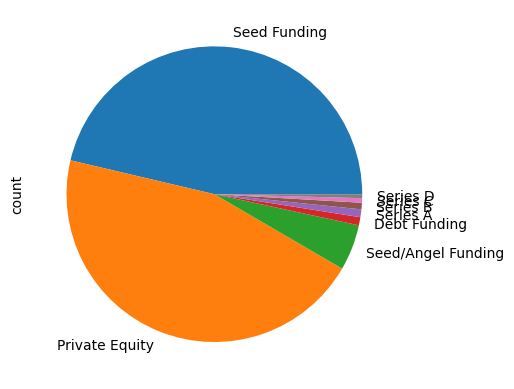

In [25]:
df['round'].value_counts().head(8).plot(kind='pie')

In [43]:
df['city'].value_counts()

city
Bangalore                 841
Mumbai                    564
New Delhi                 422
Gurgaon                   336
Pune                      105
                         ... 
India / US                  1
\\xc2\\xa0Bangalore         1
\\xc2\\xa0Mumbai            1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 107, dtype: int64

In [42]:
df['city'].value_counts().sort_values(ascending=False).head(10)

city
Bangalore    841
Mumbai       564
New Delhi    422
Gurgaon      336
Pune         105
Hyderabad     99
Chennai       97
Noida         92
Ahmedabad     38
Delhi         34
Name: count, dtype: int64

In [38]:
df['city'] = df['city'].replace({
    'Bengaluru' : 'Bangalore', 
    'Gurugram' : 'Gurgaon', 
    'Nw Delhi' : 'New Delhi'
})

<Axes: ylabel='count'>

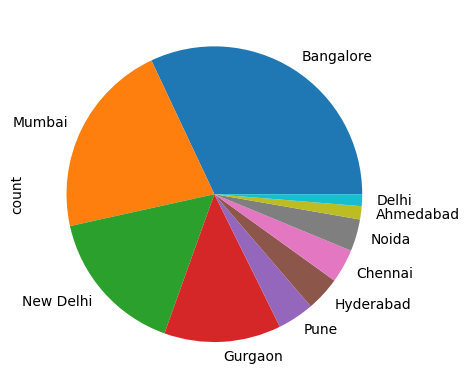

In [44]:
df['city'].value_counts().head(10).plot(kind='pie')

In [45]:
df.to_csv(file, index=False)

In [46]:
df.head()

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
1,2020-01-09,BYJU'S,E-Tech,E-learning,Bangalore,Tiger Global Management,Private Equity,1650,2020,1
2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,66,2020,1
3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bangalore,Sequoia Capital India,Series B,151,2020,1
4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,25,2020,1
5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Funding,15,2020,1


In [75]:
comp_df = df[df['startup'].str.contains("rapido", case=False, na=False)]

In [76]:
comp_df

,date,startup,vertical,subvertical,city,investors,round,amount,year,month
61,2019-08-27,Rapido Bike Taxi,Transportation,Bike Taxi,Bangalore,Westbridge Capital,Series B,32175,2019,8
504,2017-11-21,Rapido,Technology,Bike and Taxi pooling online platform,Hyderabad,"Skycatcher Fund, Aravind Sanka",Seed/Angel Funding,3,2017,11
622,2017-09-25,Rapido,Consumer Internet,Bike Aggregator Mobile App,Bangalore,Battery Road Digital Holdings LLC,Seed Funding,3,2017,9
1781,2016-04-18,Rapido,Consumer Internet,Bike Aggregator App,Bangalore,"Pawan Munjal, AdvantEdge Partners, Astarc Vent...",Private Equity,0,2016,4


In [77]:
if 'subvertical' in comp_df.columns:
    subindustry = comp_df['subvertical']
    print(subindustry)
else:
    subindustry = 'N/A'

61                                  Bike Taxi
504     Bike and Taxi pooling online platform
622                Bike Aggregator Mobile App
1781                      Bike Aggregator App
Name: subvertical, dtype: object


In [78]:
subindustry

61                                  Bike Taxi
504     Bike and Taxi pooling online platform
622                Bike Aggregator Mobile App
1781                      Bike Aggregator App
Name: subvertical, dtype: object

In [79]:
comp_df['subvertical'].values[0] if 'subvertical' in comp_df.columns else 'N/A'

'Bike Taxi'

In [80]:
comp_df['subvertical'].values[0] 

'Bike Taxi'

In [70]:
# Clean any accidental spaces from column names globally
df.columns = df.columns.str.strip()

In [71]:
df.to_csv(file, index=False)